In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("DiabetesBigData").getOrCreate()

In [3]:
from pyspark.sql.functions import col


file_path = "/content/diabetes.csv"

df = spark.read.csv(file_path, header=True, inferSchema=True)

print("Schema:")
df.printSchema()

print("First 5 rows:")
df.show(5)

Schema:
root
 |-- Pregnancies: integer (nullable = true)
 |-- Glucose: integer (nullable = true)
 |-- BloodPressure: integer (nullable = true)
 |-- SkinThickness: integer (nullable = true)
 |-- Insulin: integer (nullable = true)
 |-- BMI: double (nullable = true)
 |-- DiabetesPedigreeFunction: double (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Outcome: integer (nullable = true)

First 5 rows:
+-----------+-------+-------------+-------------+-------+----+------------------------+---+-------+
|Pregnancies|Glucose|BloodPressure|SkinThickness|Insulin| BMI|DiabetesPedigreeFunction|Age|Outcome|
+-----------+-------+-------------+-------------+-------+----+------------------------+---+-------+
|          6|    148|           72|           35|      0|33.6|                   0.627| 50|      1|
|          1|     85|           66|           29|      0|26.6|                   0.351| 31|      0|
|          8|    183|           64|            0|      0|23.3|                   0.672| 3

In [4]:
from pyspark.sql.functions import count, when


missing_counts = df.select([
    count(when(col(c).isNull(), c)).alias(c) for c in df.columns
])

missing_counts.show()

+-----------+-------+-------------+-------------+-------+---+------------------------+---+-------+
|Pregnancies|Glucose|BloodPressure|SkinThickness|Insulin|BMI|DiabetesPedigreeFunction|Age|Outcome|
+-----------+-------+-------------+-------------+-------+---+------------------------+---+-------+
|          0|      0|            0|            0|      0|  0|                       0|  0|      0|
+-----------+-------+-------------+-------------+-------+---+------------------------+---+-------+



In [5]:
from pyspark.sql.functions import when

cols_with_zero_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

df_clean = df
for c in cols_with_zero_missing:
    df_clean = df_clean.withColumn(
        c,
        when(col(c) == 0, None).otherwise(col(c))
    )


missing_after = df_clean.select([
    count(when(col(c).isNull(), c)).alias(c) for c in df_clean.columns
])
missing_after.show()

+-----------+-------+-------------+-------------+-------+---+------------------------+---+-------+
|Pregnancies|Glucose|BloodPressure|SkinThickness|Insulin|BMI|DiabetesPedigreeFunction|Age|Outcome|
+-----------+-------+-------------+-------------+-------+---+------------------------+---+-------+
|          0|      5|           35|          227|    374| 11|                       0|  0|      0|
+-----------+-------+-------------+-------------+-------+---+------------------------+---+-------+



In [6]:
df_clean = df_clean.na.drop(subset=cols_with_zero_missing)

print("Rows before cleaning:", df.count())
print("Rows after cleaning:", df_clean.count())


Rows before cleaning: 768
Rows after cleaning: 392


In [7]:
outcome_counts = df_clean.groupBy("Outcome").count()
outcome_counts.show()

+-------+-----+
|Outcome|count|
+-------+-----+
|      1|  130|
|      0|  262|
+-------+-----+



In [8]:
df_clean.describe().show()

+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------------+------------------+-------------------+
|summary|       Pregnancies|           Glucose|     BloodPressure|     SkinThickness|           Insulin|               BMI|DiabetesPedigreeFunction|               Age|            Outcome|
+-------+------------------+------------------+------------------+------------------+------------------+------------------+------------------------+------------------+-------------------+
|  count|               392|               392|               392|               392|               392|               392|                     392|               392|                392|
|   mean|3.3010204081632653|122.62755102040816| 70.66326530612245|29.145408163265305|156.05612244897958|33.086224489795896|      0.5230459183673473|30.864795918367346|0.33163265306122447|
| stddev|   3.2114244562103|30.860780631724722|12.4960915649

In [9]:
from pyspark.sql.functions import when

df_transformed = df_clean.withColumn(
    "AgeGroup",
    when(col("Age") < 30, "Under 30")
    .when((col("Age") >= 30) & (col("Age") < 40), "30-39")
    .when((col("Age") >= 40) & (col("Age") < 50), "40-49")
    .otherwise("50+")
)

In [10]:
df_transformed = df_transformed.withColumn(
    "GlucoseLevel",
    when(col("Glucose") < 100, "Normal")
    .when((col("Glucose") >= 100) & (col("Glucose") < 126), "Prediabetic")
    .otherwise("DiabeticRange")
)

In [11]:
from pyspark.sql.functions import round as spark_round

total_rows = df_transformed.count()

outcome_pct = (
    df_transformed
    .groupBy("Outcome")
    .agg(
        count("*").alias("count")
    )
    .withColumn("percentage", spark_round(col("count") * 100.0 / total_rows, 2))
)

outcome_pct.show()

+-------+-----+----------+
|Outcome|count|percentage|
+-------+-----+----------+
|      1|  130|     33.16|
|      0|  262|     66.84|
+-------+-----+----------+



In [12]:
from pyspark.sql.functions import round as spark_round, avg

avg_by_outcome = (
    df_transformed
    .groupBy("Outcome")
    .agg(
        spark_round(avg("Glucose"), 2).alias("avg_glucose"),
        spark_round(avg("BMI"), 2).alias("avg_BMI"),
        spark_round(avg("Age"), 2).alias("avg_age")
    )
)

avg_by_outcome.show()

+-------+-----------+-------+-------+
|Outcome|avg_glucose|avg_BMI|avg_age|
+-------+-----------+-------+-------+
|      1|     145.19|  35.78|  35.94|
|      0|     111.43|  31.75|  28.35|
+-------+-----------+-------+-------+



In [13]:
age_outcome = (
    df_transformed
    .groupBy("AgeGroup", "Outcome")
    .agg(count("*").alias("count"))
    .orderBy("AgeGroup", "Outcome")
)

age_outcome.show()

+--------+-------+-----+
|AgeGroup|Outcome|count|
+--------+-------+-----+
|   30-39|      0|   43|
|   30-39|      1|   35|
|   40-49|      0|   20|
|   40-49|      1|   26|
|     50+|      0|    9|
|     50+|      1|   21|
|Under 30|      0|  190|
|Under 30|      1|   48|
+--------+-------+-----+



In [14]:
glucose_outcome = (
    df_transformed
    .groupBy("GlucoseLevel", "Outcome")
    .agg(count("*").alias("count"))
    .orderBy("GlucoseLevel", "Outcome")
)

glucose_outcome.show()

+-------------+-------+-----+
| GlucoseLevel|Outcome|count|
+-------------+-------+-----+
|DiabeticRange|      0|   68|
|DiabeticRange|      1|   94|
|       Normal|      0|   94|
|       Normal|      1|    8|
|  Prediabetic|      0|  100|
|  Prediabetic|      1|   28|
+-------------+-------+-----+



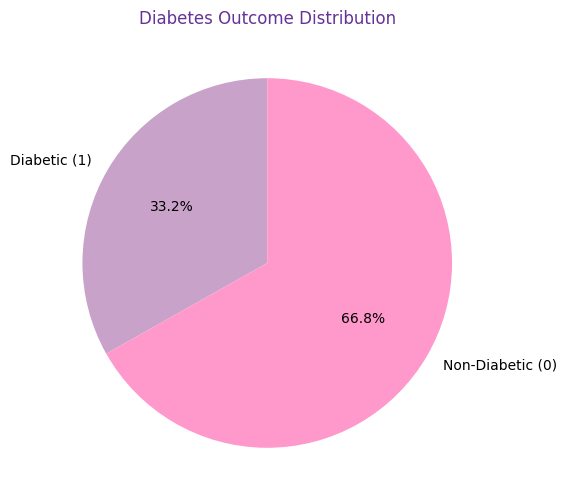

In [15]:
import matplotlib.pyplot as plt


outcome_pd = outcome_counts.toPandas()

plt.figure(figsize=(6,6))
plt.pie(
    outcome_pd['count'],
    labels=['Diabetic (1)', 'Non-Diabetic (0)'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#C8A2C8', '#ff99cc']
)
plt.title("Diabetes Outcome Distribution", color='#663399')
plt.show()

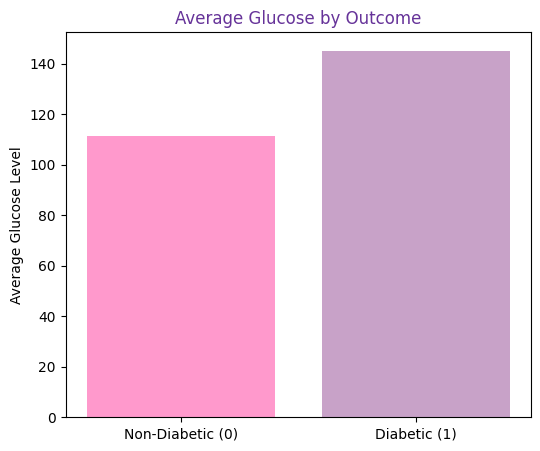

In [16]:
from pyspark.sql.functions import avg, round as spark_round


avg_glucose = (
    df_clean.groupBy("Outcome")
    .agg(spark_round(avg("Glucose"), 2).alias("avg_glucose"))
)


avg_glucose_pd = avg_glucose.toPandas()

plt.figure(figsize=(6,5))
plt.bar(
    avg_glucose_pd['Outcome'],
    avg_glucose_pd['avg_glucose'],
    color=['#C8A2C8', '#ff99cc']
)
plt.xticks([0,1], ['Non-Diabetic (0)', 'Diabetic (1)'])
plt.ylabel("Average Glucose Level")
plt.title("Average Glucose by Outcome", color='#663399')
plt.show()

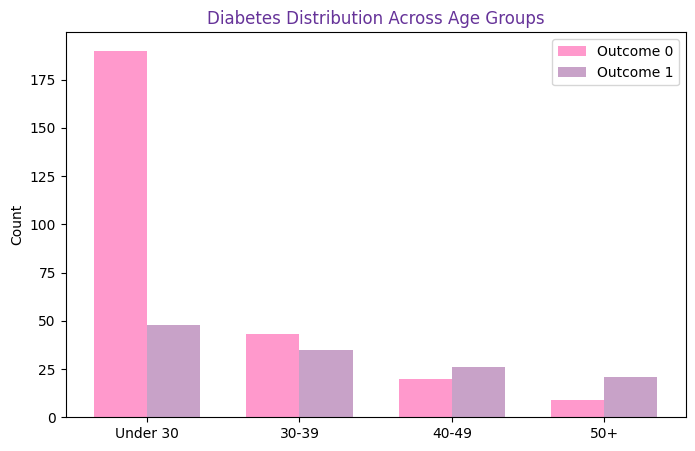

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

age_pd = age_outcome.toPandas()


age_groups = age_pd['AgeGroup'].unique()
age_groups_sorted = ["Under 30", "30-39", "40-49", "50+"]
age_pd['AgeGroup'] = pd.Categorical(age_pd['AgeGroup'], categories=age_groups_sorted, ordered=True)
age_pd = age_pd.sort_values('AgeGroup')


x = np.arange(len(age_groups_sorted))
width = 0.35

counts_0 = age_pd[age_pd['Outcome'] == 0]['count'].values
counts_1 = age_pd[age_pd['Outcome'] == 1]['count'].values

plt.figure(figsize=(8,5))

plt.bar(x - width/2, counts_0, width, label='Outcome 0', color='#ff99cc')
plt.bar(x + width/2, counts_1, width, label='Outcome 1', color='#C8A2C8')

plt.xticks(x, age_groups_sorted)
plt.ylabel("Count")
plt.title("Diabetes Distribution Across Age Groups", color='#663399')
plt.legend()
plt.show()

In [19]:
output_path = "/content/diabetes_results"

outcome_pct.coalesce(1).write.mode("overwrite").csv(output_path + "/outcome_pct", header=True)
avg_by_outcome.coalesce(1).write.mode("overwrite").csv(output_path + "/avg_by_outcome", header=True)
age_outcome.coalesce(1).write.mode("overwrite").csv(output_path + "/age_outcome", header=True)
glucose_outcome.coalesce(1).write.mode("overwrite").csv(output_path + "/glucose_outcome", header=True)